# 02 — RNN From Scratch, Vanishing Gradients, and LSTM/GRU Gating (Concept)

**Overview:** implement a vanilla RNN cell from scratch, demonstrate vanishing gradients over
a long sequence, and walk through LSTM/GRU gating conceptually (with a from-scratch LSTM cell
forward pass).

**Required libraries:** `numpy`, `matplotlib`.

Connects to: `01_cnn_from_scratch.ipynb` (another weight-sharing architecture, now across time
instead of space) and `16_backpropagation` (gradients flowing backward, now through time).
Leads to: `03_attention_and_transformer_block.ipynb`.

### Abbreviations used in this notebook

| Term | Full form | What it is |
|---|---|---|
| **RNN** | Recurrent Neural Network | Processes sequences step by step, carrying a hidden state. |
| **LSTM** | Long Short-Term Memory | RNN with gates and a cell state that eases vanishing gradients. |
| **GRU** | Gated Recurrent Unit | Simpler gated RNN with update and reset gates. |
| **CNN** | Convolutional Neural Network | Network using sliding-filter convolutions; strong on images. |

## 0. Environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)


## 1. A vanilla RNN cell, from scratch

**Equation:** `h_t = tanh(W_hh @ h_{t-1} + W_xh @ x_t + b)` — the SAME weights are reused at
every time step (weight sharing across time, just like a CNN kernel shares weights across
space).

In [2]:
def rnn_cell_forward(x_t, h_prev, W_xh, W_hh, b):
    return np.tanh(W_hh @ h_prev + W_xh @ x_t + b)

hidden_size, input_size = 4, 3
W_xh = rng.normal(scale=0.5, size=(hidden_size, input_size))
W_hh = rng.normal(scale=0.5, size=(hidden_size, hidden_size))
b = np.zeros(hidden_size)

sequence_length = 5
inputs = [rng.normal(size=input_size) for _ in range(sequence_length)]
h = np.zeros(hidden_size)

hidden_states = [h]
for t, x_t in enumerate(inputs):
    h = rnn_cell_forward(x_t, h, W_xh, W_hh, b)
    hidden_states.append(h)
    print(f"t={t}: hidden state = {h.round(3)}")

assert len(hidden_states) == sequence_length + 1
assert hidden_states[0].shape == (hidden_size,)


t=0: hidden state = [ 0.567 -0.925 -0.06   0.689]
t=1: hidden state = [-0.723  0.872  0.23  -0.214]
t=2: hidden state = [ 0.077 -0.828 -0.208  0.21 ]
t=3: hidden state = [-0.058  0.292  0.2    0.346]
t=4: hidden state = [-0.344  0.18  -0.031 -0.254]


## 2. Vanishing gradients over a long sequence

💡 **Intuition:** backpropagating through time multiplies the same Jacobian (`∂h_t/∂h_{t-1}`,
dominated by `W_hh` and `tanh`'s derivative, which is ≤1) over and over -- if that Jacobian's
magnitude is consistently < 1, the gradient shrinks exponentially with sequence length.

original W_hh spectral norm: 1.019 -> rescaled to: 0.900


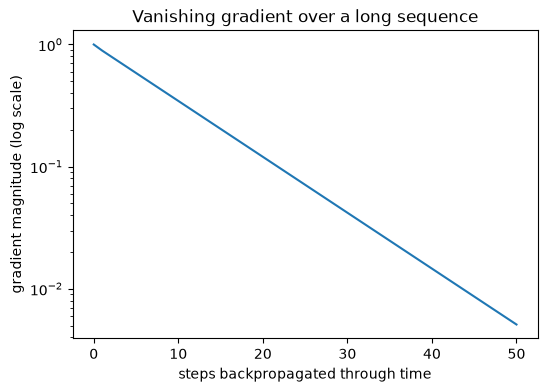

gradient magnitude after 50 steps: 5.10e-03
(started at 1.0 -- this is the vanishing gradient problem, made concrete)


In [3]:
def rnn_gradient_through_time(W_hh, sequence_length, h_init_scale=0.1):
    """Simulates how a gradient signal shrinks when backpropagated through `sequence_length`
    RNN steps, by repeatedly multiplying by tanh'(h) * W_hh (the per-step Jacobian)."""
    grad_magnitude = 1.0
    magnitudes = [grad_magnitude]
    h = np.ones(W_hh.shape[0]) * h_init_scale
    for _ in range(sequence_length):
        tanh_derivative = 1 - np.tanh(h) ** 2     # tanh'(h), always in (0, 1]
        # Spectral norm (ord=2, the largest singular value) is what actually governs how much
        # repeated multiplication can grow or shrink a vector -- the default Frobenius norm can
        # overstate this by up to sqrt(rank) and would make this demo unreliable.
        jacobian_norm = np.linalg.norm(tanh_derivative[:, None] * W_hh, ord=2)
        grad_magnitude *= jacobian_norm
        magnitudes.append(grad_magnitude)
        h = np.tanh(W_hh @ h)
    return magnitudes

long_sequence_length = 50

# Scale W_hh so its spectral norm is comfortably below 1 -- this is specifically what makes the
# per-step Jacobian shrink the gradient (a spectral norm > 1 would instead cause gradients to
# EXPLODE, the other face of the same instability). Real RNN weight initializations don't
# control for this directly, which is exactly why vanishing/exploding gradients are a problem
# in practice rather than a deliberate, comfortable choice.
spectral_norm = np.linalg.norm(W_hh, ord=2)
W_hh_vanishing = W_hh * (0.9 / spectral_norm)
print(f"original W_hh spectral norm: {spectral_norm:.3f} -> rescaled to: "
      f"{np.linalg.norm(W_hh_vanishing, ord=2):.3f}")

magnitudes = rnn_gradient_through_time(W_hh_vanishing, long_sequence_length)

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(magnitudes)
ax.set_xlabel("steps backpropagated through time"); ax.set_ylabel("gradient magnitude (log scale)")
ax.set_title("Vanishing gradient over a long sequence")
plt.show()

print(f"gradient magnitude after {long_sequence_length} steps: {magnitudes[-1]:.2e}")
print(f"(started at 1.0 -- this is the vanishing gradient problem, made concrete)")
assert magnitudes[-1] < magnitudes[0] * 0.01   # dramatic shrinkage over a long sequence


## 3. LSTM gating, conceptually, with a from-scratch forward pass

**Equations** (one LSTM cell step):
```
forget_gate = sigmoid(W_f @ [h_prev, x_t] + b_f)
input_gate  = sigmoid(W_i @ [h_prev, x_t] + b_i)
output_gate = sigmoid(W_o @ [h_prev, x_t] + b_o)
candidate   = tanh(W_c @ [h_prev, x_t] + b_c)
cell_state  = forget_gate * cell_prev + input_gate * candidate
hidden      = output_gate * tanh(cell_state)
```

💡 **Intuition:** the forget/input gates give the network a learned, data-dependent way to
decide what to keep vs discard in its memory (`cell_state`), rather than being forced to
constantly reshrink everything through a single `tanh`, as a vanilla RNN does.

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def lstm_cell_forward(x_t, h_prev, c_prev, params):
    combined = np.concatenate([h_prev, x_t])
    forget_gate = sigmoid(params["W_f"] @ combined + params["b_f"])
    input_gate = sigmoid(params["W_i"] @ combined + params["b_i"])
    output_gate = sigmoid(params["W_o"] @ combined + params["b_o"])
    candidate = np.tanh(params["W_c"] @ combined + params["b_c"])

    c_t = forget_gate * c_prev + input_gate * candidate
    h_t = output_gate * np.tanh(c_t)
    return h_t, c_t, {"forget": forget_gate, "input": input_gate, "output": output_gate}

combined_size = hidden_size + input_size
lstm_params = {
    "W_f": rng.normal(scale=0.3, size=(hidden_size, combined_size)), "b_f": np.zeros(hidden_size),
    "W_i": rng.normal(scale=0.3, size=(hidden_size, combined_size)), "b_i": np.zeros(hidden_size),
    "W_o": rng.normal(scale=0.3, size=(hidden_size, combined_size)), "b_o": np.zeros(hidden_size),
    "W_c": rng.normal(scale=0.3, size=(hidden_size, combined_size)), "b_c": np.zeros(hidden_size),
}

h_lstm, c_lstm = np.zeros(hidden_size), np.zeros(hidden_size)
for t, x_t in enumerate(inputs):
    h_lstm, c_lstm, gates = lstm_cell_forward(x_t, h_lstm, c_lstm, lstm_params)
    print(f"t={t}: forget_gate~{gates['forget'].mean():.3f}, input_gate~{gates['input'].mean():.3f}, "
          f"output_gate~{gates['output'].mean():.3f}")

assert h_lstm.shape == (hidden_size,)
assert c_lstm.shape == (hidden_size,)
print("\nUnlike the vanilla RNN, the cell_state pathway (c_t) can carry information forward "
      "largely unchanged when forget_gate is near 1 and input_gate is near 0 -- this is "
      "specifically what mitigates vanishing gradients over long sequences.")


t=0: forget_gate~0.468, input_gate~0.460, output_gate~0.537
t=1: forget_gate~0.514, input_gate~0.527, output_gate~0.469
t=2: forget_gate~0.503, input_gate~0.476, output_gate~0.549
t=3: forget_gate~0.489, input_gate~0.513, output_gate~0.451
t=4: forget_gate~0.511, input_gate~0.490, output_gate~0.533

Unlike the vanilla RNN, the cell_state pathway (c_t) can carry information forward largely unchanged when forget_gate is near 1 and input_gate is near 0 -- this is specifically what mitigates vanishing gradients over long sequences.


## 4. GRU: a simpler alternative (concept)

💡 **Intuition:** GRU merges LSTM's forget and input gates into a single "update gate," and has
no separate cell state -- fewer parameters, often comparable performance, and is conceptually
a simplification rather than a different mechanism.

```
update_gate = sigmoid(W_z @ [h_prev, x_t])
reset_gate  = sigmoid(W_r @ [h_prev, x_t])
candidate   = tanh(W_h @ [reset_gate * h_prev, x_t])
h_t = (1 - update_gate) * h_prev + update_gate * candidate
```

## 5. Connection to what's next

Both the vanilla RNN's sequential bottleneck (can't parallelize across time) and its vanishing
gradient problem are exactly what motivated the shift to attention, covered next in
`03_attention_and_transformer_block.ipynb` — attention lets every position look at every other
position directly, in one step, instead of propagating information step by step.

## 6. Interview questions
1. Why does a vanilla RNN's gradient tend to vanish (or explode) over long sequences?
2. What specific mechanism in an LSTM mitigates vanishing gradients, compared to a vanilla RNN?
3. What's the practical difference between LSTM and GRU, and why might you choose one over the other?
4. Why can't a vanilla RNN be parallelized across time steps during training the way a Transformer's attention can?
5. What role does the forget gate play, and what happens if it's always close to 1?

## 7. Exercises
1. Repeat the vanishing-gradient experiment with a smaller-magnitude `W_hh` and observe the gradient shrink even faster.
2. Implement a from-scratch GRU cell forward pass, following the equations in section 4.
3. Compare the LSTM's `cell_state` trajectory over a sequence to the vanilla RNN's `hidden_state` trajectory, for the same input sequence.

## 8. Summary

✅ Vanilla RNNs propagate information step-by-step and suffer from vanishing gradients over
long sequences; LSTM/GRU gating mitigates this with learned, data-dependent memory control.
Next: `03_attention_and_transformer_block.ipynb`.